# Classification in Machine learning - Logistic Regression


Implementation of Logistic Regression Classification Algorithm using Scikit_Learn, Pandas, Numpy Libraries. How to write code for implementation and evaluate the Algorithm. You will learn Data Exploration, Data Preprocessing, Model building and Evaluation of Machine Learning Model on Real world Dataset. You are going to learn how to predict heart disease early on  in patients using the heart disease dataset.


## Step 1 — Import Required Libraries
**Task:** Complete the imports.

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)



## Step 2 — Load the Heart Dataset
**Task:** Read the CSV file from the codebase and display top rows.

In [3]:
df = pd.read_csv("heart.csv")
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


## Step 3 — Explore the Dataset
**Task:** Print shape, columns, missing values, and statistics.

In [4]:
print("Shape:", df.shape)

print("\nColumns:", df.columns.tolist())

print("\nMissing values:\n", df.isnull().sum())

print("\nTarget Class Distribution:\n", df['target'].value_counts())

df.describe()


Shape: (1025, 14)

Columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Missing values:
 age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Target Class Distribution:
 target
1    526
0    499
Name: count, dtype: int64


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


## Step 4 — Define Features (X) and Target (y)
**Task:** Use all 13 vars as X and target as y

In [5]:
X = df.drop(columns=["target"])     
y = df["target"]                   # (0 = No Disease, 1 = Disease)

print("X shape:", X.shape)
print("y shape:", y.shape)



X shape: (1025, 13)
y shape: (1025,)


## Step 5 — Split Dataset into Training and Test Sets
**Task:** Use `train_test_split` with a test size and random state.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,       
    random_state=42  
)

print("X_train:", X_train.shape, "X_test:", X_test.shape)


X_train: (820, 13) X_test: (205, 13)


## Step 5.5 — Scaling


In [8]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled features shape (train):", X_train_scaled.shape)
print("Scaled features shape (test): ", X_test_scaled.shape)


Scaled features shape (train): (820, 13)
Scaled features shape (test):  (205, 13)


## Step 6 — Train the Logistic Regression Model
**Task:** Create and fit the model. Print intercept and coefficient.

In [10]:
model = LogisticRegression(random_state=42, max_iter=1000)
model.fit(X_train_scaled, y_train)

print("Intercept:", model.intercept_[0])
print("\nTop 5 Coefficients:")
pd.Series(model.coef_[0], index=X.columns).sort_values(ascending=False).head()



Intercept: -0.12874355612396704

Top 5 Coefficients:


cp         0.885835
thalach    0.652826
slope      0.343605
restecg    0.140804
age       -0.006734
dtype: float64

## Step 7 — Make Predictions
**Task:** Predict class outcomes and class probabilities on the test set and display first 5 rows of results.

In [11]:
y_pred = model.predict(X_test_scaled)
y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]

pd.DataFrame({
    "ActualTarget": y_test.values,
    "PredictedTarget": y_pred,
    "PredictedProbability": y_pred_proba
}).head()


,ActualTarget,PredictedTarget,PredictedProbability
0,1,1,0.974910
1,1,1,0.996911
2,0,0,0.014694
3,1,1,0.971024
4,0,0,0.042745


## Step 8 — Evaluate the Model
**Task:** Compute Accuracy, Precision, Recall, and F1 Score

In [12]:
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy :", acc)
print("Precision:", prec)
print("Recall   :", rec)
print("F1 Score :", f1)
print("\nClassification Report:\n", classification_report(y_test, y_pred))



Accuracy : 0.7951219512195122
Precision: 0.7563025210084033
Recall   : 0.8737864077669902
F1 Score : 0.8108108108108109

Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.72      0.78       102
           1       0.76      0.87      0.81       103

    accuracy                           0.80       205
   macro avg       0.80      0.79      0.79       205
weighted avg       0.80      0.80      0.79       205



# Visualization Section

## Step 9 — Target Class Distribution Plot
**Task:** Create a bar plot of the target variable.

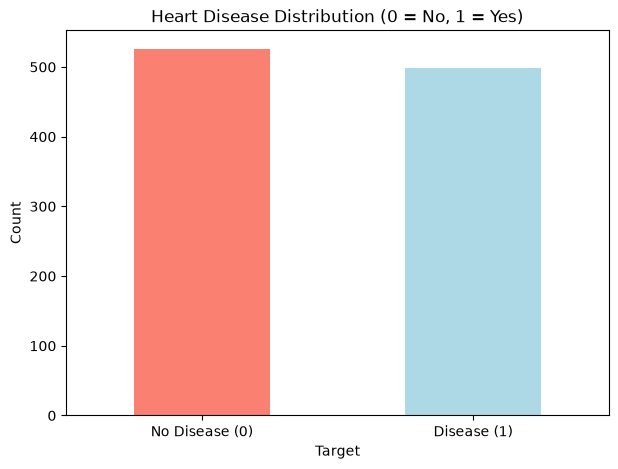

In [14]:
plt.figure(figsize=(7, 5))
df['target'].value_counts().plot(kind='bar', color=['salmon', 'lightblue'])
plt.title("Heart Disease Distribution (0 = No, 1 = Yes)")
plt.xlabel("Target")
plt.ylabel("Count")
plt.xticks(ticks=[0, 1], labels=["No Disease (0)", "Disease (1)"], rotation=0)
plt.show()



## Step 10 — Feature Importance
**Task:** Plot the horizontal bar chart of scaled feature coefficients.

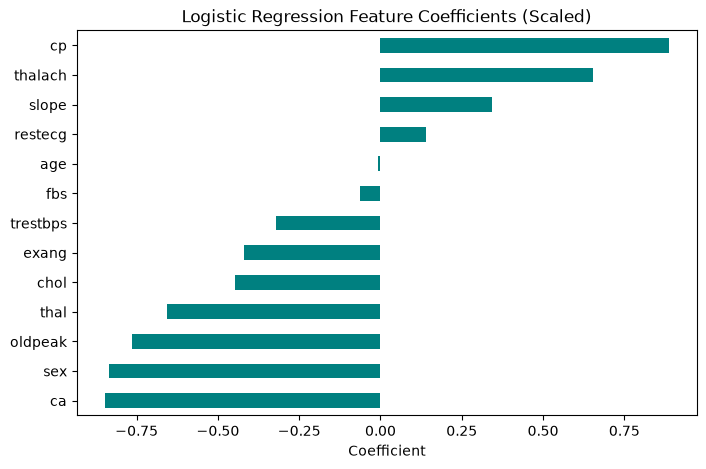

In [15]:
coef_series = pd.Series(model.coef_[0], index=X.columns).sort_values()

plt.figure(figsize=(8, 5))
coef_series.plot(kind='barh', color='teal')
plt.title("Logistic Regression Feature Coefficients (Scaled)")
plt.xlabel("Coefficient")
plt.show()

